In [1]:
## импорт библиотек
## работа с матрицами, математика
import numpy as np
## отображение и графики
import matplotlib.pyplot as plt
## работа с геометрией и сеткой
import gmsh

# Семинар. Стационарное тепловое состояние пластины: метод конечных элементов в Python

**Тема:** Двумерная стационарная теплопроводность, линейные треугольные конечные элементы, сборка матриц и граничные условия I–III рода.

**Задача:** Рассчитать поле температуры квадратной пластины

**Результат:** Собственный, небольшой МКЭ-решатель на `NumPy`.

**Предварительные знания:** массивы NumPy, циклы, линейные системы, предыдущий семинар по плоской ферме.

**Ориентировочное время:** 90–120 минут, включая задания. Для короткой пары раздел сходимости и дополнительный кейс можно дать самостоятельно.

**Цели занятия:**
1. Перейти от дифференциального уравнения к матричной системе;
2. Построить треугольную сетку и понять индексацию узлов;
3. Вычислить матрицу одного элемента и собрать глобальную матрицу;
4. Задать конвективный теплообмен, тепловой поток и заданную температуру.

## 1. Физическая постановка

Рассматриваем квадратную пластину $L_x=L_y=5$ мм с постоянной теплопроводностью $\lambda=45$ Вт/(м·К). Решаем **стационарную** задачу **без внутренних источников тепла**:

$$
\nabla\cdot(\lambda\nabla T)=0.
$$

Здесь $T(x,y)$ — температура, $\lambda$ — теплопроводность. Пластину рассматриваем как двумерную модель с толщиной $t$; в расчетных интегралах толщина учитывается явно.

**Знаки:** внешний тепловой поток $q_{\mathrm{out}}$ положителен, когда тепло подводится к телу. Закон Фурье: $\mathbf q=-\lambda\nabla T$.

| Вид условия | Физический смысл | Уравнение на границе |
|---|---|---|
| I (Дирихле) | задана температура | $T=T_b$ |
| II (Неймана) | задан выходящий поток | $-\lambda\nabla T\cdot\mathbf n=q_{\mathrm{out}}$ |
| III (Робина) | теплообмен с окружающей средой | $-\lambda\nabla T\cdot\mathbf n=h(T-T_\infty)$ |


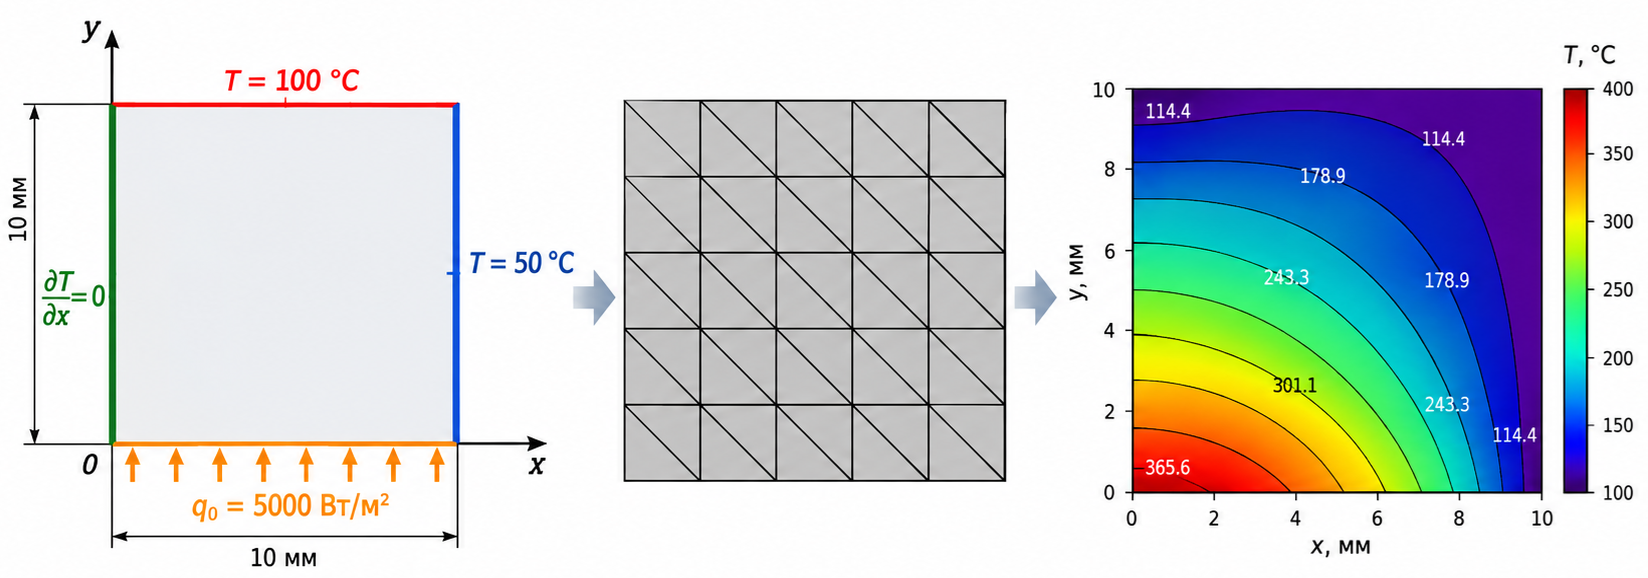

Геометрическая модель расчетой области и свойства материала

In [2]:
lam = 45.0                   # Вт/(м·К), теплопроводность
th = 1e-3                    # м: единичная толщина


## 2. Геометрия и конечно-элементная сетка

Геометрия исследуемой пластины импортируется из файла `geom.step`, после чего с помощью `Gmsh` формируется конечно-элементная сетка.

При этом геометрия импортируется **без предварительной разметки границ** — отдельным сторонам пластины не присвоены номера или физические группы, которые можно было бы использовать для задания граничных условий.

Поскольку в нашем случае рассматривается простая прямоугольная пластина, мы сможем самостоятельно определить её границы по координатам узлов и связности конечных элементов.

Из полученной сетки извлечём данные, необходимые для дальнейших расчётов, и представим их в следующем формате:

- `pnts[i] = [x_i, y_i]` — координаты узла $i$;
- `elms[e] = [i, j, k]` — номера трёх узлов элемента $e$.

В дальнейшем на основе этих массивов будем вычислять матрицы теплопроводности отдельных элементов, собирать глобальную систему уравнений и определять участки границы для задания граничных условий.



**Инициализация и завершение работы Gmsh**

**Gmsh** — это отдельное программное приложение, предназначенное для работы с геометрией и генерации конечно-элементных сеток. В нашем случае мы будем управлять им непосредственно из **JupyterLab** с помощью Python-библиотеки `gmsh`, не используя графический интерфейс приложения.

Перед началом работы необходимо инициализировать Gmsh:

```python
gmsh.initialize()
```

Эта команда запускает программную среду Gmsh и подготавливает её к импорту геометрии, построению сетки и получению данных о конечных элементах.

После завершения всех операций с геометрией и сеткой необходимо корректно завершить работу Gmsh:

```python
gmsh.finalize()
```

При этом ранее извлечённые в массивы NumPy координаты узлов `pnts` и номера элементов `elms` сохраняются и могут использоваться для дальнейших расчётов.

**Важно:** `gmsh.initialize()` и `gmsh.finalize()` образуют пару команд, ограничивающих работу с Gmsh. Повторная инициализация без завершения предыдущей сессии может привести к ошибкам. Поэтому в JupyterLab необходимо учитывать порядок выполнения ячеек.


In [3]:
## Инициализируем чтение и подготовим сетки
gmsh.initialize()
geom_path = '_geom/geom.stp'
mesh_path = '_geom/mesh.msh'
gmsh.option.setNumber("Geometry.OCCImportLabels", 1)            # на всякий случай 

Генерация сетки по геометрии

In [4]:
gmsh.open(geom_path)
# Размер элемента
gmsh.option.setNumber("Mesh.MeshSizeMin", 0.5)
gmsh.option.setNumber("Mesh.MeshSizeMax", 0.5)
# Генерация 2D-сетки
gmsh.model.mesh.generate(2)
gmsh.write(mesh_path)

Чтение сетки из полученного файла

In [5]:
# Читаем уже сгенерированную сетку
gmsh.open(mesh_path)

Все элементы сетки в таком файле храняться без форматирования просто последовательно в соответствующем разделе. Обращаясь к разделу нужно привести формат к удобному в использовании

In [6]:
node_tags, pnts, _ = gmsh.model.mesh.getNodes()
pnts = pnts.reshape(-1, 3)                            
# Для 2D задачи оставляем x, y
pnts = pnts[:, :2]*1e-3

In [7]:
_, _, elms = gmsh.model.mesh.getElements(2)
elms = elms[0].reshape(-1, 3)

интересно, что `elms` содержит номера элементов, а они начинаются с `1`, а мы хотим индексировать с `0` обращаясь к индексу `pnts`. Поэтому просто вычтем 1

In [8]:
elms = elms -1

In [9]:
# сохраним количество элементов, чтобы потом можно было писать циклы по ним
nn = len(pnts)
ne = len(elms) 

In [10]:
#нужно закончить работу gmsh
gmsh.finalize()

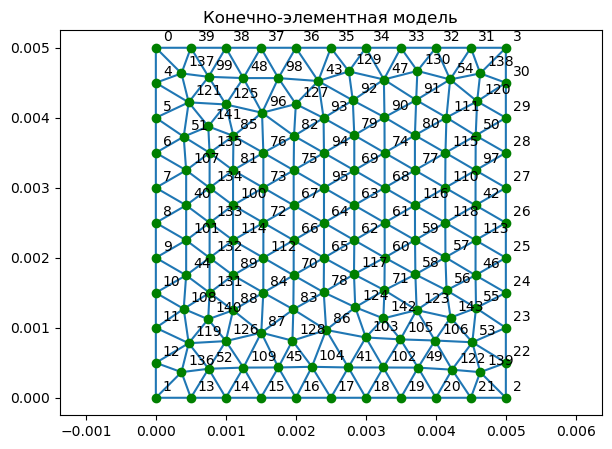

In [11]:
fig, ax = plt.subplots(figsize=(7,5))
plt.title('Конечно-элементная модель')
ax.triplot(pnts[:,0]  , pnts[:,1]  , elms)
ax.plot(pnts[:,0], pnts[:,1], 'go', lw=1.0)
texts = [ax.text(pnts[i,0]+1e-4, pnts[i,1]+1e-4, '%s' %i) for i in range(nn)]
plt.axis('equal')
plt.show()

### Посмотреть индексы узлов одного элемента

**Мини-задание:** определить координаты всех трех узлов элемента № 0.

In [12]:
eid = 0
node_ids = elms[eid]
coords = pnts[node_ids]

print('Элемент:', eid)
print('Индексы узлов:', node_ids)
print('Координаты, мм:\n', coords * 1e3)

Элемент: 0
Индексы узлов: [ 41 103  86]
Координаты, мм:
 [[2.75       0.4330127 ]
 [2.99969582 0.86156268]
 [2.43293901 0.96859013]]


## 3. Свойства отдельного элемента

Рассмотрим **линейный треугольный конечный элемент** $e_i$, показанный на рисунке. Его вершинами являются узлы $i$, $j$ и $m$ с координатами:

$$
i(x_i,y_i), \qquad j(x_j,y_j), \qquad m(x_m,y_m).
$$

В каждом из узлов определяются искомые значения температуры $T_i$, $T_j$ и $T_m$.

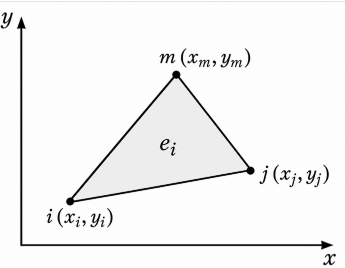


### Аппроксимация температурного поля

В пределах линейного треугольного конечного элемента распределение температуры аппроксимируется через её значения в трёх узлах:

$$
T(x,y)=N_i(x,y)T_i+N_j(x,y)T_j+N_m(x,y)T_m,
$$

где $N_i$, $N_j$, $N_m$ — **функции формы**, определяющие вклад узловых температур в температуру произвольной точки элемента.

Функции формы обладают следующим свойством: в собственном узле соответствующая функция равна единице, а в остальных узлах элемента — нулю. Например:

$$
N_i(x_i,y_i)=1,\qquad
N_i(x_j,y_j)=N_i(x_m,y_m)=0.
$$

В матричной форме аппроксимация записывается следующим образом:

$$
T(x,y)=[N]\{T\}_e,
$$

где

$$
[N]=
\begin{pmatrix}
N_i & N_j & N_m
\end{pmatrix},
\qquad
\{T\}_e=
\begin{pmatrix}
T_i\\
T_j\\
T_m
\end{pmatrix}.
$$

Для линейного треугольного элемента функции формы являются линейными функциями координат $x$ и $y$. Поэтому температура внутри элемента также изменяется по линейному закону, а её производные по координатам постоянны.

### Геометрические характеристики элемента

Для определения функций формы и последующего формирования матрицы теплопроводности необходимо знать координаты узлов и площадь треугольного элемента.

Рассмотрим два вектора, образованные сторонами треугольника с общей вершиной $i$:

$$
\mathbf{r}_{ij}=
\begin{pmatrix}
x_j-x_i\\
y_j-y_i
\end{pmatrix},
\qquad
\mathbf{r}_{im}=
\begin{pmatrix}
x_m-x_i\\
y_m-y_i
\end{pmatrix}.
$$

Модуль векторного произведения этих векторов равен площади построенного на них параллелограмма. Поскольку площадь треугольника в два раза меньше, получаем:

$$
A_e=\frac12
\left|
(x_j-x_i)(y_m-y_i)
-
(x_m-x_i)(y_j-y_i)
\right|.
$$

Полученное выражение можно записать через определитель:

$$
\boxed{
A_e=\frac12
\left|
\det
\begin{pmatrix}
1 & x_i & y_i\\
1 & x_j & y_j\\
1 & x_m & y_m
\end{pmatrix}
\right|
}
$$

Обозначим определитель через $\Delta_e$:

$$
\Delta_e=
\det
\begin{pmatrix}
1 & x_i & y_i\\
1 & x_j & y_j\\
1 & x_m & y_m
\end{pmatrix}.
$$

Тогда:

$$
A_e=\frac{|\Delta_e|}{2}.
$$

**Знак определителя зависит от порядка обхода узлов:** при обходе против часовой стрелки $\Delta_e>0$, а по часовой стрелке $\Delta_e<0$. Геометрическая площадь $A_e$ всегда положительна.

### Определение функций формы

Для линейного треугольного элемента функции формы записываются следующим образом:

$$
N_i(x,y)=\frac{a_i+b_ix+c_iy}{\Delta_e},
$$

$$
N_j(x,y)=\frac{a_j+b_jx+c_jy}{\Delta_e},
$$

$$
N_m(x,y)=\frac{a_m+b_mx+c_my}{\Delta_e}.
$$

Коэффициенты $a_i$, $a_j$, $a_m$ определяются по координатам узлов:

$$
\mathbf a=
\begin{pmatrix}
x_jy_m-x_my_j\\
x_my_i-x_iy_m\\
x_iy_j-x_jy_i
\end{pmatrix}.
$$

Аналогично вводятся векторы геометрических коэффициентов:

$$
\mathbf b=
\begin{pmatrix}
y_j-y_m\\
y_m-y_i\\
y_i-y_j
\end{pmatrix},
\qquad
\mathbf c=
\begin{pmatrix}
x_m-x_j\\
x_i-x_m\\
x_j-x_i
\end{pmatrix}.
$$

Знаменатель $\Delta_e$ обеспечивает выполнение условий интерполяции: каждая функция формы равна единице в соответствующем узле и нулю в остальных.

Поскольку функции формы линейны, их производные постоянны внутри элемента:

$$
\frac{\partial N_i}{\partial x}=\frac{b_i}{\Delta_e},
\qquad
\frac{\partial N_i}{\partial y}=\frac{c_i}{\Delta_e}.
$$

Аналогичные выражения справедливы для узлов $j$ и $m$.

Следовательно, производные температуры можно выразить через узловые значения:

$$
\frac{\partial T}{\partial x}
=
\frac{1}{\Delta_e}
\left(
b_iT_i+b_jT_j+b_mT_m
\right),
$$

$$
\frac{\partial T}{\partial y}
=
\frac{1}{\Delta_e}
\left(
c_iT_i+c_jT_j+c_mT_m
\right).
$$

Введём **матрицу геометрических коэффициентов элемента**:

$$
\mathbf H=
\begin{pmatrix}
b_i & b_j & b_m\\
c_i & c_j & c_m
\end{pmatrix}.
$$

Тогда обе производные температуры можно объединить в одно матричное выражение:

$$
\boxed{
\nabla T=
\begin{pmatrix}
\dfrac{\partial T}{\partial x}\\[6pt]
\dfrac{\partial T}{\partial y}
\end{pmatrix}
=
\frac{1}{\Delta_e}\mathbf H\{T\}_e
}
$$

Таким образом, **градиент температуры постоянен в пределах каждого линейного треугольного элемента**.

Если узлы перечислены против часовой стрелки, то $\Delta_e=2A_e$. В общем случае для вычисления производных необходимо учитывать знак определителя.

### Получение элементной матрицы теплопроводности из функционала

Для стационарной задачи теплопроводности без внутренних источников теплоты решение может быть получено из **условия стационарности функционала**:

$$
\Phi(T)=
\frac{\lambda t}{2}
\int_S
\left[
\left(\frac{\partial T}{\partial x}\right)^2+
\left(\frac{\partial T}{\partial y}\right)^2
\right]dS
-
t\int_{\Gamma_2}q_0T\,dL
+
\frac{\alpha t}{2}
\int_{\Gamma_3}(T-T_\infty)^2\,dL.
$$

Здесь:

- $S$ — площадь пластины;
- $t$ — толщина пластины, принимаемая постоянной;
- $\lambda$ — коэффициент теплопроводности материала;
- $\Gamma_2$ — участок границы с заданным тепловым потоком;
- $q_0$ — плотность заданного теплового потока;
- $\Gamma_3$ — участок границы с конвективным теплообменом;
- $\alpha$ — коэффициент теплоотдачи;
- $T_\infty$ — температура окружающей среды.

**Принятое соглашение о знаках:** положительный тепловой поток $q_0$ направлен внутрь пластины. Поэтому соответствующее слагаемое функционала имеет знак минус.

Функционал содержит три составляющие:

1. **Первое слагаемое** характеризует теплопроводность внутри пластины.
2. **Второе слагаемое** учитывает заданный тепловой поток (ГУ II рода).
3. **Третье слагаемое** описывает конвективный теплообмен (ГУ III рода).

Граничные условия I рода задают известную температуру на соответствующем участке границы:

$$
T|_{\Gamma_1}=T_\Gamma.
$$

Они не образуют дополнительного интеграла в функционале, а рассматриваются как ограничения на допустимые значения температур при определении его стационарного значения.

### Формирование матрицы теплопроводности элемента

Рассмотрим первое слагаемое функционала, соответствующее теплопроводности внутри отдельного конечного элемента:

$$
\Phi_e^{(\lambda)}=
\frac{\lambda t}{2}
\int_{A_e}
(\nabla T)^{\mathsf T}(\nabla T)\,dA.
$$

Подставим полученное ранее выражение для градиента температуры:

$$
\nabla T=\frac{1}{\Delta_e}\mathbf H\{T\}_e.
$$

Тогда:

$$
\Phi_e^{(\lambda)}=
\frac{\lambda t}{2\Delta_e^2}
\int_{A_e}
\{T\}_e^{\mathsf T}
\mathbf H^{\mathsf T}\mathbf H
\{T\}_e\,dA.
$$

Для линейного треугольного элемента матрица $\mathbf H$ постоянна и не зависит от координат внутри элемента. Вектор узловых температур $\{T\}_e$ также не зависит от координат интегрирования.

Следовательно, интегрирование сводится к умножению на площадь элемента:

$$
\Phi_e^{(\lambda)}=
\frac{\lambda t A_e}{2\Delta_e^2}
\{T\}_e^{\mathsf T}
\mathbf H^{\mathsf T}\mathbf H
\{T\}_e.
$$

Учитывая, что

$$
\Delta_e^2=4A_e^2,
$$

получаем:

$$
\Phi_e^{(\lambda)}=
\frac{\lambda t}{8A_e}
\{T\}_e^{\mathsf T}
\mathbf H^{\mathsf T}\mathbf H
\{T\}_e.
$$

Данное выражение представляет собой квадратичную форму:

$$
\Phi_e^{(\lambda)}=
\frac12
\{T\}_e^{\mathsf T}
\mathbf K_e
\{T\}_e.
$$

Сравнивая полученные выражения, определим **матрицу теплопроводности отдельного треугольного конечного элемента**:

$$
\boxed{
\mathbf K_e=
\frac{\lambda t}{4A_e}
\mathbf H^{\mathsf T}\mathbf H
}
$$



### Условие стационарности функционала

В методе конечных элементов непрерывное температурное поле аппроксимируется через конечное число узловых температур. После подстановки функций формы функционал становится функцией этих неизвестных:

$$
\Phi=\Phi(T_1,T_2,\ldots,T_n).
$$

**Условие стационарности функционала** означает, что его первые производные по всем неизвестным узловым температурам должны быть равны нулю:

$$
\boxed{
\frac{\partial\Phi}{\partial T_i}=0,
\qquad i=1,2,\ldots,n.
}
$$

Здесь дифференцирование выполняется по неизвестным температурам; значения, заданные граничными условиями I рода, считаются фиксированными.

После формирования элементных матриц и векторов функционал всей системы можно представить в виде:

$$
\Phi=
\frac12\mathbf T^{\mathsf T}\mathbf K\mathbf T
-
\mathbf T^{\mathsf T}\mathbf F+C,
$$

где $\mathbf K$ — глобальная матрица, $\mathbf F$ — вектор тепловых нагрузок, а $C$ — слагаемое, не зависящее от неизвестных температур.

Учитывая симметричность матрицы $\mathbf K$, получаем:

$$
\frac{\partial\Phi}{\partial\mathbf T}
=
\mathbf K\mathbf T-\mathbf F.
$$

Следовательно, условие стационарности приводит к системе линейных алгебраических уравнений:

$$
\boxed{
\mathbf K\mathbf T=\mathbf F.
}
$$

Таким образом, **глобальная система МКЭ получается из условия равенства нулю производных функционала по неизвестным узловым температурам**.
Полученная матрица имеет размерность $3\times3$ и определяется координатами узлов элемента, теплопроводностью материала и толщиной пластины.

**Важно:** несмотря на то что знак определителя зависит от порядка обхода узлов, выражение для элементной матрицы через положительную площадь $A_e$ справедливо при любом порядке их перечисления.

### Переход к глобальной системе уравнений

Полученная матрица $\mathbf K_e$ описывает теплопроводность внутри отдельного треугольного элемента.

Для расчёта температурного поля всей пластины необходимо объединить матрицы отдельных элементов в **глобальную матрицу теплопроводности**.

Условие стационарности функционала по неизвестным узловым температурам приводит к системе линейных алгебраических уравнений:

$$
\mathbf K_{\mathrm{glob}}\mathbf T=
\mathbf F_{\mathrm{glob}}.
$$

При формировании глобальной системы учитываются как теплопроводно**ГУ II рода:** формируют дополнительные составляющие вектора тепловой нагрузки $\mathbf F_{\mathrm{glob}}$.
- **ГУ III рода:** формируют дополнительные составляющие матрицы $\mathbf K_{\mathrm{glob}}$ и вектора $\mathbf F_{\mathrm{glob}}$.

Далее рассмотрим алгоритм сборки глобальной матрицы из элементных матриц и последующее задание граничных условий.
формируют дополнительные слагаемые как в матрице $\mathbf K_{\mathrm{glob}}$, так и в векторе $\mathbf F_{\mathrm{glob}}$.

Их математическая реализация будет подробно рассмотрена в следующих разделах семинара.


ционала по неизвестным узловым температурам**.


In [13]:
def get_kel(element, km, th=th):
    i , j , m = element
    xi, yi = pnts[i]
    xj, yj = pnts[j]
    xm, ym = pnts[m]
    area = 0.5 * abs((xj-xi)*(ym-yi) - (yj-yi)*(xm-xi))
    b = np.array([yj-ym, ym-yi, yi-yj])
    c = np.array([xm-xj, xi-xm, xj-xi])
    H = np.array([b, c])
    Kel = km * th / (4 * area) * (H.T @ H)                     # используем не поэлементное умножение, а матричное
    return Kel   

In [14]:
Ke0 = get_kel(elms[0], km = lam)
print('Матрица одного элемента:\n', Ke0)
print('Симметрична:', np.allclose(Ke0, Ke0.T))
print('Суммы строк (должны быть близки к 0):', Ke0.sum(axis=1))

Матрица одного элемента:
 [[ 0.02776266 -0.01978022 -0.00798244]
 [-0.01978022  0.03232785 -0.01254763]
 [-0.00798244 -0.01254763  0.02053007]]
Симметрична: True
Суммы строк (должны быть близки к 0): [-1.73472348e-18  3.46944695e-18  0.00000000e+00]


## 4. Сборка глобальной матрицы

Для каждого элемента узнаём три глобальных индекса и прибавляем вклад $K_e$ к соответствующим позициям глобальной $K$.


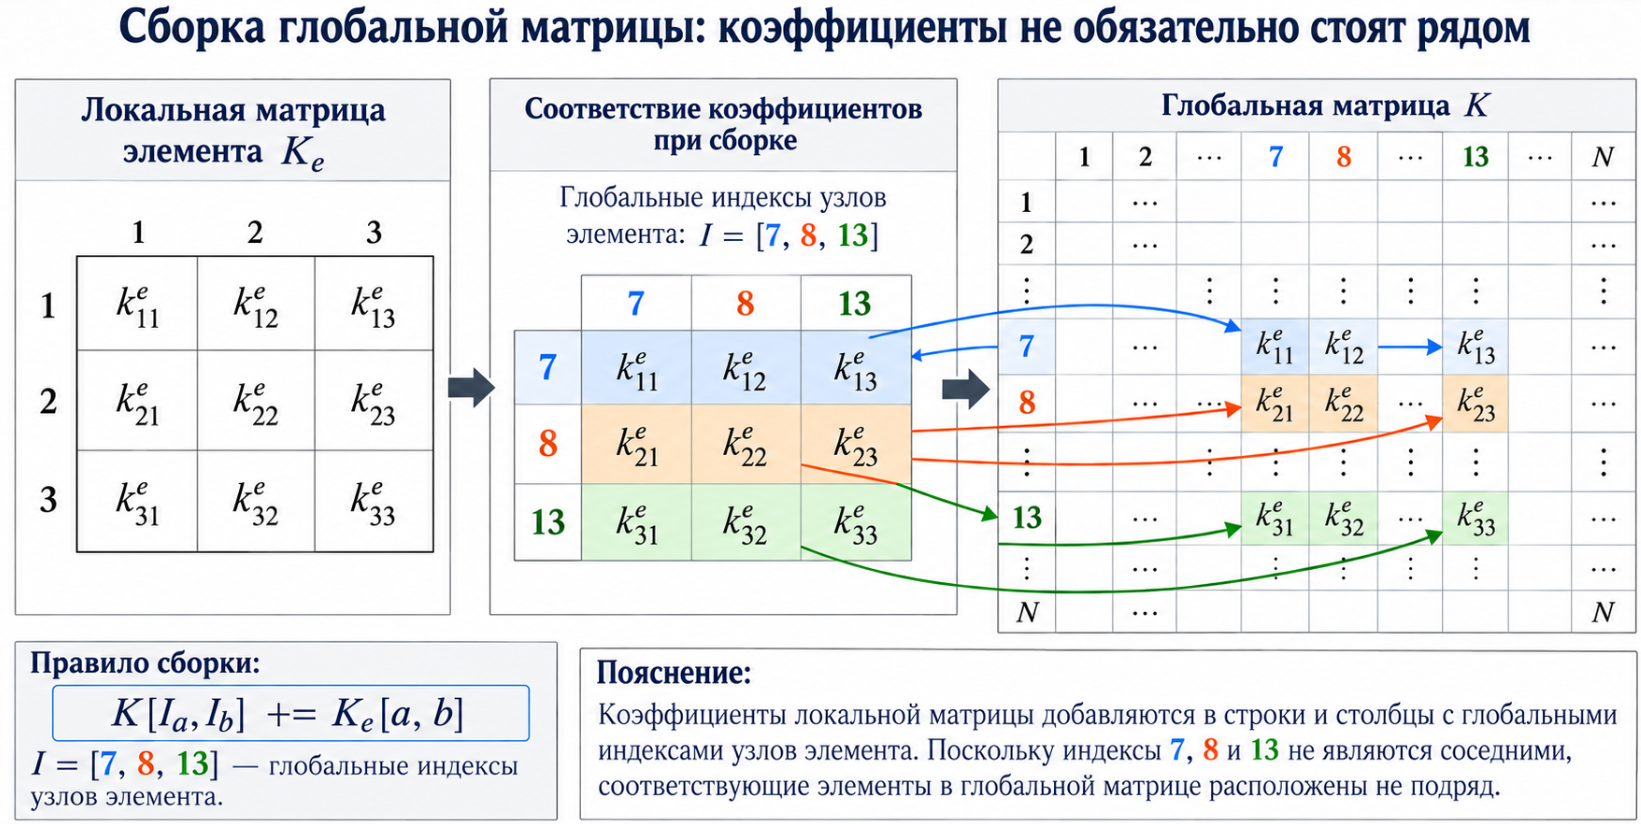

In [15]:
Kglob  = np.zeros([nn, nn])
Fglob = np.zeros(nn)

In [16]:
# чтобы сформировать подмассив по выбранным индексам нужно использовать np.ix_
for el in range(ne):
    IndX =elms[el]
    IndXArr = np.ix_(IndX, IndX)
    Kglob[IndXArr] += get_kel(elms[el], km = lam)    

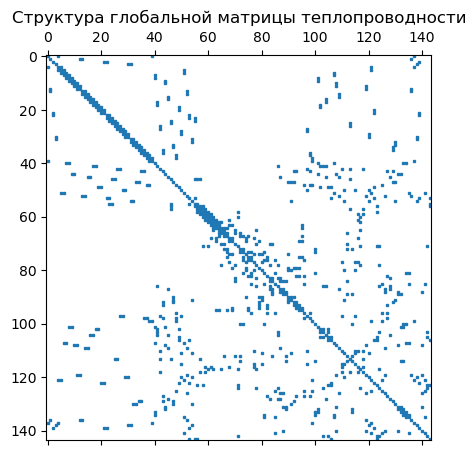

In [17]:
plt.figure(figsize=(5, 5))
plt.spy(Kglob, markersize=2)
plt.title('Структура глобальной матрицы теплопроводности')
plt.show()

Стоит отметить, что не нулей не так то и много. Это важное замечание, чтобы не хранить нули обычно используются **разреженные матрицы** `scipy.sparse`, но мы не будем так поступать, потому что задача небольшая. Ради интересно можно посмотреть сумму элементов построчно..... почему так ?

## 5. Идентификация граничных рёбер

Поскольку рассматриваемая геометрия представляет собой простой квадрат, идентификацию границ можно выполнить по координатам узлов.

Для этого последовательно:

1. **Определим граничные узлы** — выберем узлы, координаты которых соответствуют заданной стороне пластины ($x=0$, $x=L_x$, $y=0$ или $y=L_y$).
2. **Найдём прилегающие элементы** — выберем треугольники, у которых два узла принадлежат рассматриваемой границе.
3. **Выделим граничные рёбра** — для каждого такого треугольника определим пару узлов, образующих ребро на границе пластины.
4. **Вычислим длины рёбер** по координатам их концов.

При задании теплового потока (ГУ II рода) и конвективного теплообмена (ГУ III рода) необходимо учитывать длины граничных рёбер, поскольку соответствующие слагаемые функционала вычисляются интегрированием по границе пластины.


### 5.1. Определение узлов на границе

По очередно будем выбирать границы обращаясь к координате известной
- $x = 0 $ - **bottom**
- $y = 0 $ - **left**
- $x = 5 $ - **top**
- $y = 5 $ - **right**

Переберём все узлы сетки и проверим их координаты. Если координата $y$ узла равна нулю, добавим его номер в массив `sel_nds`.

**Результат:** массив `sel_nds`, содержащий глобальные номера узлов выбранной границы.


In [18]:
def sel_nds(pnts, axis='x', value=0):
    coord = 0 if axis == 'x' else 1
    nds = []
    for nd in range(len(pnts)):
        if np.isclose(pnts[nd, coord], value):
            nds.append(nd)
    return np.array(nds, dtype=int)    

### 5.2. Определение элементов, прилегающих к границе

Каждый треугольный конечный элемент содержит три узла, номера которых хранятся в массиве `elms`.

Если **два узла треугольного элемента принадлежат выбранной границе**, то соединяющее их ребро может являться граничным.

Для определения таких элементов используем функцию `np.isin()`, которая проверяет принадлежность узлов элемента массиву `sel_nds`.

Полученный логический массив содержит значения `True` для узлов, принадлежащих границе, и `False` для остальных. Сумма этих значений позволяет определить количество граничных узлов в каждом элементе.

**Результат:** массив `sel_elms`, содержащий номера элементов, у которых ровно два узла принадлежат выбранной границе.


In [19]:
def sel_elms(elms, sel_nds):
    sel_elms = []
    for el in range(ne):
        n = np.isin(elms[el], sel_nds).sum()
        if n == 2:
            sel_elms.append(el)
    return np.array(sel_elms, dtype=int) 

### 5.3. Формирование массива граничных рёбер

Для задания граничных условий II и III рода необходимо знать не только узлы границы, но и то, какие из них соединены между собой рёбрами конечных элементов.

Используя найденные на предыдущем этапе элементы `sel_elms`, для каждого из них выберем два узла, принадлежащие массиву `sel_nds`.

Эти два узла образуют граничное ребро.

**Результат:** двумерный массив `edges`, в котором каждая строка содержит номера двух узлов одного граничного ребра:

$$
\mathrm{edges} =
\begin{pmatrix}
i_1 & j_1 \\
i_2 & j_2 \\
\vdots & \vdots \\
i_m & j_m
\end{pmatrix}
$$

Здесь $m$ — количество найденных граничных рёбер.

Порядок расположения рёбер в массиве не имеет значения для последующего вычисления их длин и задания обычных скалярных граничных условий теплопроводности.


In [20]:
def sel_edges(elms, sel_elms, sel_nds):
    edges = []
    for el in sel_elms:
        edge = elms[el][np.isin(elms[el], sel_nds)]
        edges.append(edge)
    return np.array(edges, dtype=int) 


### 5.4. Определение длин граничных рёбер и формирование данных о границах

При задании граничных условий II и III рода необходимо учитывать протяжённость каждого граничного ребра, поскольку тепловая нагрузка определяется интегрированием по соответствующему участку границы.

Для ребра, соединяющего узлы $i$ и $j$, длина определяется по координатам:

$$
L_{ij}=\sqrt{(x_j-x_i)^2+(y_j-y_i)^2}.
$$

Для вычисления расстояния между узлами используем функцию `np.linalg.norm()`, которая определяет евклидову норму вектора разности их координат.

В результате для каждой стороны пластины мы получаем четыре массива:

- `nodes` — номера узлов, принадлежащих границе;
- `elements` — номера конечных элементов, имеющих ребро на этой границе;
- `edges` — пары номеров узлов, образующих граничные рёбра;
- `L` — длины соответствующих рёбер, расположенные в том же порядке, что и в массиве `edges`.

Чтобы не хранить эти данные в отдельных переменных для каждой стороны пластины, объединим их в **словарь `boundary`**.

Каждому ключу словаря (`left`, `right`, `bottom`, `top`) соответствует набор данных о выбранной границе, содержащий узлы, элементы, рёбра и их длины.

Например, после формирования словаря:

- `boundary['bottom']['nodes']` — узлы нижней границы;
- `boundary['bottom']['edges']` — рёбра нижней границы;
- `boundary['bottom']['length']` — длины этих рёбер.

Таким образом, словарь `boundary` объединяет геометрические и топологические данные, необходимые для последующего задания граничных условий на каждой стороне пластины.


In [21]:
boundary = {}

for name, axis, value in [
    ('left',   'x', 0),
    ('right',  'x', 5*1e-3),
    ('bottom', 'y', 0),
    ('top',    'y', 5*1e-3)
]:
    nodes = sel_nds(pnts, axis, value)
    elements = sel_elms(elms, nodes)
    edges = sel_edges(elms, elements, nodes)
    
    L = []
    for nd1, nd2 in edges:
        L.append(np.linalg.norm(pnts[nd2] - pnts[nd1]))
    L = np.array(L)
    
    boundary[name] = {
        'nodes': nodes,
        'elements': elements,
        'edges': edges,
        'length': L
    }

Отобразим получившиеся границы

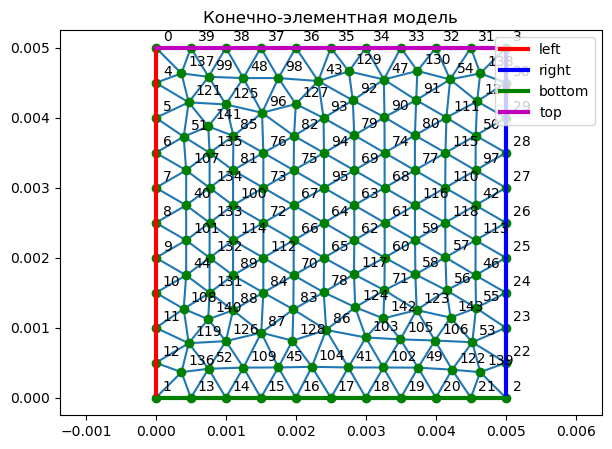

In [22]:
colors = ['r', 'b', 'g', 'm']
fig, ax = plt.subplots(figsize=(7,5))
plt.title('Конечно-элементная модель')
ax.triplot(pnts[:,0]  , pnts[:,1]  , elms)
ax.plot(pnts[:,0], pnts[:,1], 'go', lw=1.0)
texts = [ax.text(pnts[i,0]+1e-4, pnts[i,1]+1e-4, '%s' %i) for i in range(nn)]
for i, bc in enumerate(boundary):
    edges = boundary[bc]['edges']
    plt.plot(pnts[edges, 0].T, pnts[edges, 1].T, color=colors[i], lw=3)
    plt.plot([], [], color=colors[i], lw=3, label=bc)
plt.axis('equal')
plt.legend(loc='upper right')
plt.show()


## 6. Граничные условия I рода: заданная температура

**Граничные условия I рода (условия Дирихле)** предполагают, что температура на определённом участке границы пластины известна:

$$
T|_{\Gamma_1}=T_{\Gamma},
$$

где $T_{\Gamma}$ — заданная температура, а $\Gamma_1$ — соответствующий участок границы пластины.

Для задания ГУ I рода достаточно знать **номера узлов**, принадлежащих выбранной границе. Длины граничных рёбер в данном случае не требуются.

После сборки глобальной матрицы теплопроводности получаем систему линейных алгебраических уравнений:

$$
\mathbf K_{\mathrm{glob}}\mathbf T=\mathbf F_{\mathrm{glob}}.
$$

Для каждого граничного узла $i$ необходимо обеспечить выполнение условия:

$$
T_i=T_{\Gamma}.
$$

В отличие от ГУ II и III рода, заданная температура не формирует дополнительного интегрального слагаемого в функционале, а является **ограничением на допустимые значения узловых температур**.

Поскольку часть температур заранее известна, они не являются неизвестными величинами задачи. Поэтому условие стационарности функционала применяется только к свободным узловым температурам:

$$
\boxed{
\frac{\partial\Phi}{\partial T_i}=0,
\qquad i\in f,
}
$$

где $f$ — множество узлов с неизвестными температурами.

Есть два способа учёта заданных температур в глобальной системе уравнений.

### Способ 1. Замена уравнений для узлов с известной температурой

Наиболее простой способ заключается в замене уравнения для каждого узла $i$, температура которого известна.

Для этого необходимо:

1. Обнулить все коэффициенты строки $i$ глобальной матрицы теплопроводности.
2. Установить диагональный коэффициент $K_{ii}=1$.
3. Присвоить соответствующему компоненту вектора правой части значение $F_i=T_{\Gamma}$.

В результате уравнение для выбранного узла принимает вид:

$$
1\cdot T_i=T_{\Gamma}.
$$

Например, для системы из трёх уравнений:

$$
\begin{pmatrix}
K_{11}&K_{12}&K_{13}\\
K_{21}&K_{22}&K_{23}\\
K_{31}&K_{32}&K_{33}
\end{pmatrix}
\begin{pmatrix}
T_1\\T_2\\T_3
\end{pmatrix}
=
\begin{pmatrix}
F_1\\F_2\\F_3
\end{pmatrix}
$$

при заданной температуре $T_1=T_{\Gamma}$ получаем:

$$
\begin{pmatrix}
1&0&0\\
K_{21}&K_{22}&K_{23}\\
K_{31}&K_{32}&K_{33}
\end{pmatrix}
\begin{pmatrix}
T_1\\T_2\\T_3
\end{pmatrix}
=
\begin{pmatrix}
T_{\Gamma}\\F_2\\F_3
\end{pmatrix}.
$$

Таким образом, вместо исходного уравнения для первого узла мы непосредственно задаём известное значение температуры. Остальные уравнения сохраняются, и влияние заданной температуры на соседние узлы учитывается автоматически.

**Преимущество:** простота реализации — размерность системы не изменяется.

**Недостаток:** матрица теряет симметрию, поскольку изменяются только строки, но не соответствующие столбцы.

В нашем семинаре воспользуемся именно этим способом, поскольку он позволяет сохранить первоначальную глобальную нумерацию узлов и не требует дополнительного преобразования размеров матрицы.

### Способ 2. Исключение узлов с известной температурой

Другой подход заключается в подстановке известных значений температур непосредственно в систему уравнений с последующим исключением соответствующих неизвестных.

Рассмотрим ту же систему, для которой температура первого узла известна:

$$
T_1=T_{\Gamma}.
$$

Подставим известное значение в оставшиеся два уравнения:

$$
\begin{cases}
K_{21}T_{\Gamma}+K_{22}T_2+K_{23}T_3=F_2,\\
K_{31}T_{\Gamma}+K_{32}T_2+K_{33}T_3=F_3.
\end{cases}
$$

Перенесём слагаемые с известной температурой в правую часть:

$$
\begin{cases}
K_{22}T_2+K_{23}T_3=F_2-K_{21}T_{\Gamma},\\
K_{32}T_2+K_{33}T_3=F_3-K_{31}T_{\Gamma}.
\end{cases}
$$

Получаем сокращённую систему:

$$
\boxed{
\begin{pmatrix}
K_{22}&K_{23}\\
K_{32}&K_{33}
\end{pmatrix}
\begin{pmatrix}
T_2\\T_3
\end{pmatrix}
=
\begin{pmatrix}
F_2-K_{21}T_{\Gamma}\\
F_3-K_{31}T_{\Gamma}
\end{pmatrix}
}
$$

Таким образом, **строка и столбец**, соответствующие узлу с известной температурой, исключаются из системы. При этом влияние известной температуры учитывается в правой части оставшихся уравнений.

В общем случае разделим узлы на две группы:

- $f$ — свободные узлы, температуры которых необходимо определить;
- $c$ — узлы с известными температурами.

Тогда исходную систему можно записать в блочном виде:

$$
\begin{pmatrix}
\mathbf K_{ff}&\mathbf K_{fc}\\
\mathbf K_{cf}&\mathbf K_{cc}
\end{pmatrix}
\begin{pmatrix}
\mathbf T_f\\
\mathbf T_c
\end{pmatrix}
=
\begin{pmatrix}
\mathbf F_f\\
\mathbf F_c
\end{pmatrix}.
$$

После подстановки известных температур $\mathbf T_c$ получаем систему только для свободных узлов:

$$
\boxed{
\mathbf K_{ff}\mathbf T_f
=
\mathbf F_f-\mathbf K_{fc}\mathbf T_c
}
$$

Полученная система непосредственно соответствует условию стационарности функционала по свободным узловым температурам.

После её решения найденные температуры свободных узлов объединяются с заранее заданными температурами граничных узлов.

**Преимущества:** уменьшается размерность системы и сохраняется симметрия матрицы. При положительной теплопроводности, связной сетке и наличии необходимого закрепления температур сокращённая матрица является положительно определённой.

**Недостаток:** требуется отдельно хранить номера свободных узлов и узлов с заданной температурой, формировать сокращённую систему и восстанавливать полный вектор температур после решения.

**Важно:** если заданные температуры относятся к нескольким границам, необходимо сначала определить все узлы с известными температурами и только затем выполнять сокращение системы.


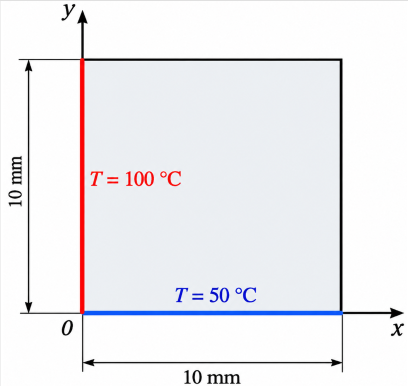

Создадим копии исходных матриц, чтобы можно было попробовать решить с разными граничными условиями

In [23]:
K1 = Kglob.copy()
F1 = Fglob.copy()

In [24]:
def bc1type(K, F, boundary, T):
    for nd in boundary['nodes']:
        K[nd, :] = 0
        K[nd, nd] = 1
        F[nd] = T
    return K, F    

Зададим соответствующие граничные условия и решим задачу

In [25]:
Tleft   = 100
Tbottom = 50
K1, F1 = bc1type(K1, F1, boundary['left'],   Tleft)
K1, F1 = bc1type(K1, F1, boundary['bottom'], Tbottom)


### Решение системы линейных алгебраических уравнений

После сборки глобальной матрицы теплопроводности и задания граничных условий получаем систему линейных алгебраических уравнений (СЛАУ):

$$
\mathbf K\mathbf T=\mathbf F,
$$

где $\mathbf K$ — матрица системы, $\mathbf F$ — вектор тепловых нагрузок, а $\mathbf T$ — искомый вектор узловых температур.

Для решения СЛАУ применяют два основных класса численных методов:

- **Прямые методы** — позволяют получить решение за конечную последовательность арифметических операций (с учётом погрешностей округления). К ним относятся метод Гаусса, LU-разложение и разложение Холецкого. При этом явное вычисление обратной матрицы не требуется.
- **Итерационные методы** — последовательно уточняют приближённое решение до достижения заданной точности. Примеры: метод Якоби, метод Гаусса — Зейделя и метод сопряжённых градиентов.

В конечно-элементных задачах глобальная матрица обычно является **разреженной**, поскольку каждый узел связан только с ограниченным числом Использованием специальных методов хранения таких матриц **sparse matrix**едних узлов. Это позволяет существенно сократ для её хранения.

При решении больших систем прямыми методами в процессе факторизации матрицы могут появляться дополнительные ненулевые элементы, что увеличивает затраты памяти и вычислительных ресурсов. Итерационные методы позволяют избежать факторизации, однако их эффективность зависит от скорости сходимости и обусловленности системы.

В нашем случае система имеет сравнительно небольшой размер, поэтому воспользуемся **прямым методом решения** с помощью функции `np.linalg.solve()` библиотеки NumPy.

Функция использует LU-разложение матрицы и находит решение системы без явного вычисления обратной матрицы:

```python
T_sol1 = np.linalg.solve(K1, F1)
```

Полученный массив `T_sol1` содержит значения температуры во всех узлах конечно-элементной сетки.

Для больших конечно-элементных моделей целесообразно использовать разреженное представление глобальной матрицы и специализированные прямые или итерационные решатели.
ользующие её структуру.


In [26]:
T_sol1 = np.linalg.solve(K1, F1)

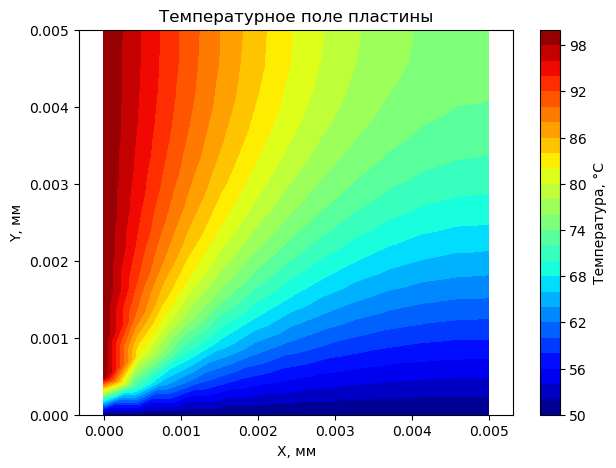

In [27]:
fig, ax = plt.subplots(figsize=(7, 5))

plt.tricontourf(pnts[:, 0], pnts[:, 1], elms, T_sol1,
                levels=30, cmap='jet')

plt.colorbar(label='Температура, °C')
plt.axis('equal')
plt.xlabel('X, мм')
plt.ylabel('Y, мм')
plt.title('Температурное поле пластины')
plt.show()


## 7. Граничные условия II рода: заданный тепловой поток

**Граничные условия II рода (условия Неймана)** предполагают, что на определённом участке границы пластины задана плотность теплового потока.

Согласно закону Фурье:

$$
\mathbf q=-\lambda\nabla T,
$$

где $\mathbf q$ — вектор плотности теплового потока, Вт/м², а $\lambda$ — коэффициент теплопроводности материала.

В нашем случае граничное условие II рода записывается в виде:

$$
\boxed{
\lambda\frac{\partial T}{\partial n}=q_{\Gamma}
}
$$

где:

- $q_{\Gamma}$ — заданная плотность теплового потока, Вт/м²;
- $n$ — направление внешней нормали к границе;
- $\Gamma_2$ — участок границы, amma}=-\mathbf q\cdot\mathbf n.
$$

В отличие от ГУ I рода, при задании теплового потока не требуется фиксировать значения узловых температур. Вместо этого необходимо **сформировать дополнительный вектор тепловой нагрузки**, который будет учитываться в правой части глобальной системы уравнений.

### Формирование вектора тепловой нагрузки

Рассмотрим граничное ребро $\Gamma_e$ длиной $L$, соединяющее узлы $i$ и $j$.

Вклад заданного теплового потока в функционал определяется выражением:

$$
\Phi_{\Gamma,e}^{(q)}
=
-t\int_{\Gamma_e}q_{\Gamma}T\,dL.
$$

Температуру вдоль ребра аппроксимируем через её значения в узлах с помощью линейных функций формы:

$$
T=N_iT_i+N_jT_j.
$$

Подставим это выражение в функционал, предполагая постоянную плотность теплового потока $q_{\Gamma}$:

$$
\Phi_{\Gamma,e}^{(q)}
=
-tq_{\Gamma}
\int_{\Gamma_e}
(N_iT_i+N_jT_j)\,dL.
$$

Для линейного граничного элемента интегралы от функций формы равны половине длины ребра:

$$
\int_{\Gamma_e}N_i\,dL
=
\int_{\Gamma_e}N_j\,dL
=
\frac{L}{2}.
$$

Это связано с тем, что функции формы линейно изменяются от 0 до 1 вдоль ребра, поэтому их среднее значение равно $1/2$.

Следовательно:

$$
\boxed{
\Phi_{\Gamma,e}^{(q)}
=
-\frac{q_{\Gamma}tL}{2}(T_i+T_j)
}
$$

### Получение элементного вектора тепловой нагрузки

Как было показано ранее, система уравнений МКЭ получается из **условия стационарности функционала по неизвестным узловым температурам**.

Вычислим производные граничного вклада по температурам узлов $i$ и $j$:

$$
\frac{\partial\Phi_{\Gamma,e}^{(q)}}{\partial T_i}
=
-\frac{q_{\Gamma}tL}{2},
$$

$$
\frac{\partial\Phi_{\Gamma,e}^{(q)}}{\partial T_j}
=
-\frac{q_{\Gamma}tL}{2}.
$$

Объединим полученные выражения в вектор:

$$
\begin{pmatrix}
\dfrac{\partial\Phi_{\Gamma,e}^{(q)}}{\partial T_i}\\[6pt]
\dfrac{\partial\Phi_{\Gamma,e}^{(q)}}{\partial T_j}
\end{pmatrix}
=
-\frac{q_{\Gamma}tL}{2}
\begin{pmatrix}
1\\
1
\end{pmatrix}.
$$

При формировании системы уравнений эти слагаемые переносятся в правую часть.

Таким образом, **элементный вектор тепловой нагрузки** определяется выражением:

$$
\boxed{
\mathbf F_{\Gamma,e}
=
\frac{q_{\Gamma}tL}{2}
\begin{pmatrix}
1\\
1
\end{pmatrix}
}
$$

При постоянной плотности теплового потока нагрузка от граничного ребра распределяется поровну между двумя его узлами.

Если тепловой поток изменяется вдоль ребра, узловые нагрузки в общем случае будут различными.

**Поскольку производные граничного вклада не зависят от неизвестных узловых температур, ГУ II рода формируют только вектор правой части и не изменяют матрицу теплопроводности.**

Знак плюс в выражении для $\mathbf F_{\Gamma,e}$ соответствует принятому соглашению: положительный поток направлен внутрь пластины.

### Учёт ГУ II рода в глобальной системе

После сборки глобальной матрицы теплопроводности система уравнений имеет вид:

$$
\mathbf K_{\mathrm{glob}}\mathbf T=\mathbf F_{\mathrm{glob}}.
$$

Для каждого граничного ребра $[i,j]$ вычисляется локальный вектор тепловой нагрузки:

$$
\mathbf F_{\Gamma,e}=
\begin{pmatrix}
F_{\Gamma,i}\\
F_{\Gamma,j}
\end{pmatrix}.
$$

Его компоненты добавляются к соответствующим компонентам глобального вектора:

$$
F_i \leftarrow F_i+F_{\Gamma,i},
$$

$$
F_j \leftarrow F_j+F_{\Gamma,j}.
$$

Если одному граничному узлу принадлежат несколько рёбер, вклады от этих рёбер **суммируются**.

Таким образом, граничные условия II рода изменяют только вектор правой части $\mathbf F_{\mathrm{glob}}$, но не изменяют матрицу теплопроводности $\mathbf K_{\mathrm{glob}}$.

### Особый случай: теплоизолированная граница

Если задано условие:

$$
q_{\Gamma}=0,
$$

то

$$
\mathbf F_{\Gamma,e}=\mathbf 0.
$$

Таким образом, теплоизолированная граница не вносит дополнительных слагаемых ни в глобальную матрицу теплопроводности, ни в вектор тепловой нагрузки.

Это **естественное граничное условие** для рассматриваемой вариационной постановки. При отсутствии заданного потока и конвективного теплообмена на участке границы теплоизоляция учитывается автоматляющее абсолютный уровень температуры.

**Важно:** фиксация одной температуры устраняет неопределённость абсолютного уровня, но не заменяет выполнение теплового баланса, необходимого для исходной задачи только с ГУ II рода.


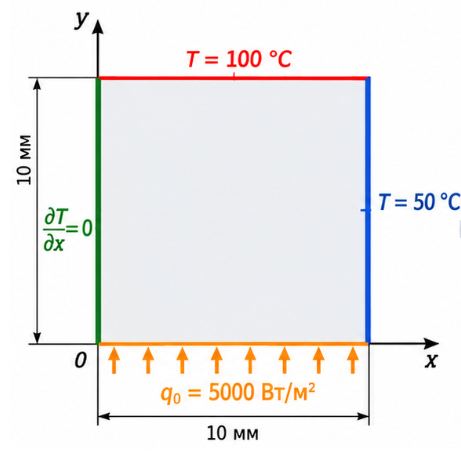

In [28]:
K2 = Kglob.copy()
F2 = Fglob.copy()

Зададим соответствующие граничные условия и решим задачу

In [29]:
def bc2type(F, boundary, q):
    edges = boundary['edges']
    L = boundary['length']
    for nds, length in zip(edges, L):
        F[nds] += q * th * length / 2      
    return F  

In [30]:
q = 50000
F2 = bc2type(F2, boundary['bottom'], q)

In [31]:
Ttop   = 100
Tright = 50
K2, F2 = bc1type(K2, F2, boundary['top'],   Ttop)
K2, F2 = bc1type(K2, F2, boundary['right'], Tright)

In [32]:
T_sol2 = np.linalg.solve(K2, F2)

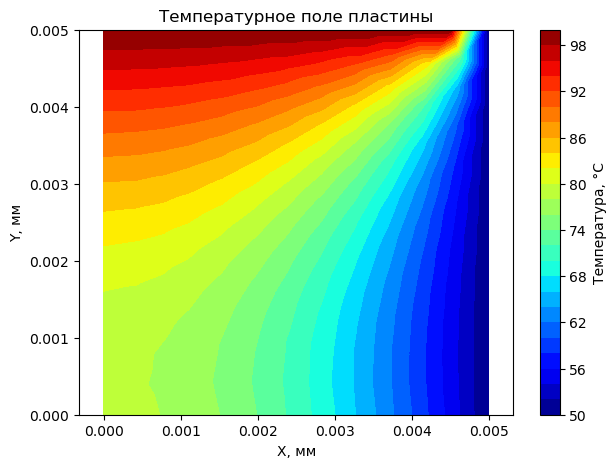

In [33]:
fig, ax = plt.subplots(figsize=(7, 5))

plt.tricontourf(pnts[:, 0], pnts[:, 1], elms, T_sol2,
                levels=30, cmap='jet')

plt.colorbar(label='Температура, °C')
plt.axis('equal')
plt.xlabel('X, мм')
plt.ylabel('Y, мм')
plt.title('Температурное поле пластины')
plt.show()


## 8. Граничные условия III рода: конвективный теплообмен

**Граничные условия III рода (условия Робина)** описывают теплообмен между поверхностью пластины и окружающей средой, температура которой известна.

В соответствии с законом Ньютона — Рихмана плотность теплового потока, направленного из пластины, определяется выражением:

$$
q_{\mathrm{out}}=\alpha(T-T_{\infty}),
$$

где:

- $\alpha$ — коэффициент теплоотдачи, Вт/(м²·К);
- $T$ — температура поверхности пластины, °C;
- $T_{\infty}$ — температура окружающей среды, °C.

С учётом закона Фурье граничное условие III рода записывается в виде:

$$
-\lambda\frac{\partial T}{\partial n}
=
\alpha(T-T_{\infty}),
$$

где $n$ — направление внешней нормали к поверхности пластины.

При $T>T_{\infty}$ тепло отводится от пластины, а при $T<T_{\infty}$ — поступает из окружающей среды.

В принятом нами соглашении, когда положительный тепловой поток направлен **внутрь пластины**, можно записать:

$$
q_{\mathrm{in}}=\alpha(T_{\infty}-T).
$$

В отличие от ГУ I рода, температура поверхности заранее неизвестна. Она определяется в процессе решения задачи.

### Формирование элементной матрицы и вектора тепловой нагрузки

Рассмотрим граничное ребро $\Gamma_e$ длиной $L$, соединяющее узлы $i$ и $j$.

Вклад конвективного теплообмена в функционал определяется выражением:

$$
\Phi_{\Gamma,e}^{(\alpha)}
=
\frac{\alpha t}{2}
\int_{\Gamma_e}(T-T_{\infty})^2\,dL.
$$

Раскроем квадрат:

$$
\Phi_{\Gamma,e}^{(\alpha)}
=
\frac{\alpha t}{2}
\int_{\Gamma_e}
\left(T^2-2TT_{\infty}+T_{\infty}^2\right)dL.
$$

Температуру вдоль ребра аппроксимируем линейными функциями формы:

$$
T=N_iT_i+N_jT_j.
$$

При постоянных $\alpha$ и $T_{\infty}$ воспользуемся свойствами линейных функций формы:

$$
\int_{\Gamma_e}N_i\,dL
=
\int_{\Gamma_e}N_j\,dL
=
\frac{L}{2},
$$

$$
\int_{\Gamma_e}N_i^2\,dL
=
\int_{\Gamma_e}N_j^2\,dL
=
\frac{L}{3},
$$

$$
\int_{\Gamma_e}N_iN_j\,dL
=
\frac{L}{6}.
$$

Следовательно:

$$
\int_{\Gamma_e}T\,dL
=
\frac{L}{2}(T_i+T_j),
$$

$$
\int_{\Gamma_e}T^2\,dL
=
\frac{L}{3}(T_i^2+T_iT_j+T_j^2).
$$

Подставим эти выражения в функционал:

$$
\boxed{
\Phi_{\Gamma,e}^{(\alpha)}
=
\frac{\alpha tL}{6}(T_i^2+T_iT_j+T_j^2)
-
\frac{\alpha tLT_{\infty}}{2}(T_i+T_j)
+
\frac{\alpha tLT_{\infty}^2}{2}
}
$$

Последнее слагаемое не зависит от неизвестных узловых температур. Поэтому при дифференцировании функционала оно обращается в ноль и не влияет на решение задачи.

### Получение элементной матрицы и вектора нагрузки

Как было показано ранее, система уравнений МКЭ получается из **условия стационарности функционала по неизвестным узловым температурам**.

Вычислим производные полученного граничного вклада по температурам узлов $i$ и $j$:

$$
\frac{\partial\Phi_{\Gamma,e}^{(\alpha)}}{\partial T_i}
=
\frac{\alpha tL}{6}(2T_i+T_j)
-
\frac{\alpha tLT_{\infty}}{2},
$$

$$
\frac{\partial\Phi_{\Gamma,e}^{(\alpha)}}{\partial T_j}
=
\frac{\alpha tL}{6}(T_i+2T_j)
-
\frac{\alpha tLT_{\infty}}{2}.
$$

Объединим полученные выражения в матричную форму:

$$
\begin{pmatrix}
\dfrac{\partial\Phi_{\Gamma,e}^{(\alpha)}}{\partial T_i}\\[6pt]
\dfrac{\partial\Phi_{\Gamma,e}^{(\alpha)}}{\partial T_j}
\end{pmatrix}
=
\frac{\alpha tL}{6}
\begin{pmatrix}
2&1\\
1&2
\end{pmatrix}
\begin{pmatrix}
T_i\\
T_j
\end{pmatrix}
-
\frac{\alpha tLT_{\infty}}{2}
\begin{pmatrix}
1\\
1
\end{pmatrix}.
$$

Полученное выражение имеет вид:

$$
\frac{\partial\Phi_{\Gamma,e}^{(\alpha)}}{\partial\{T\}_{\Gamma}}
=
\mathbf K_{\Gamma,e}\{T\}_{\Gamma}
-
\mathbf F_{\Gamma,e}.
$$

Отсюда получаем **элементную матрицу теплоотдачи**:

$$
\boxed{
\mathbf K_{\Gamma,e}
=
\frac{\alpha tL}{6}
\begin{pmatrix}
2&1\\
1&2
\end{pmatrix}
}
$$

и **элементный вектор тепловой нагрузки**:

$$
\boxed{
\mathbf F_{\Gamma,e}
=
\frac{\alpha tLT_{\infty}}{2}
\begin{pmatrix}
1\\
1
\end{pmatrix}
}
$$

Таким образом, граничные условия III рода формируют одновременно:

- **Элементную матрицу теплоотдачи** $\mathbf K_{\Gamma,e}$, поскольку тепловой поток зависит от неизвестной температуры поверхности.
- **Элементный вектор тепловой нагрузки** $\mathbf F_{\Gamma,e}$, учитывающий известную температуру окружающей среды.

Полученные выражения представляют собой вклад граничного ребра в общую систему уравнений. Условие стационарности применяется к **полному функционалу пластины**, после суммирования вкладов всех конечных элементов и граничных рёбер.

### Учёт ГУ III рода в глобальной системе

После сборки элементных матриц теплопроводности имеем:

$$
\mathbf K_{\mathrm{glob}}\mathbf T=\mathbf F_{\mathrm{glob}}.
$$

Для каждого граничного ребра $[i,j]$ вычисляются матрица $\mathbf K_{\Gamma,e}$ размером $2\times2$ и вектор $\mathbf F_{\Gamma,e}$ размером $2$.

Их коэффициенты добавляются в соответствующие позиции глобальной матрицы и вектора:

$$
\begin{pmatrix}
K_{ii}&K_{ij}\\
K_{ji}&K_{jj}
\end{pmatrix}
\leftarrow
\begin{pmatrix}
K_{ii}&K_{ij}\\
K_{ji}&K_{jj}
\end{pmatrix}
+
\mathbf K_{\Gamma,e},
$$

$$
\begin{pmatrix}
F_i\\
F_j
\end{pmatrix}
\leftarrow
\begin{pmatrix}
F_i\\
F_j
\end{pmatrix}
+
\mathbf F_{\Gamma,e}.
$$

Если узел принадлежит нескольким граничным рёбрам, их вклады **суммируются**.

В результате глобальная система учитывает одновременно теплопроводность внутри пластины и конвективный теплообмен на её границах.

**Важно:** при используемом в нашем семинаре способе задания фиксированных температур ГУ III рода необходимо учитывать до применения ГУ I рода.

### Особенности ГУ III рода

1. В отличие от ГУ I рода, температура на границе не фиксируется.
2. В отличие от ГУ II рода, тепловой поток зависит от неизвестной температуры поверхности.
3. При постоянных $\alpha$ и $T_{\infty}$ задача остаётся линейной.
4. ГУ III рода изменяют одновременно глобальную матрицу и вектор правой части.
5. При увеличении $\alpha$ температура поверхности стремится к температуре окружающей среды $T_{\infty}$, если остальные параметры и граничные условия остаются неизменными.

Таким образом, граничные условия III рода позволяют моделировать теплообмен пластины с газом или жидкостью, не задавая заранее температуру её поверхности.
\infty}$ на участке конвекции, если остальные параметры и граничные условия остаются неизменными.

Таким образом, граничные условия III рода позволяют моделировать теплообмен пластины с газом или жидкостью, не задавая заранее температуру её поверхности.


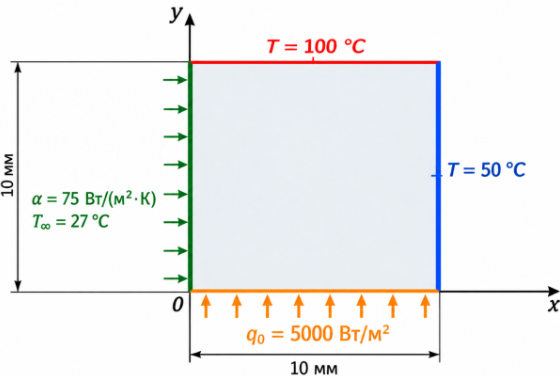

In [34]:
K3 = Kglob.copy()
F3 = Fglob.copy()

Зададим соответствующие граничные условия и решим задачу

In [35]:
def bc3type(K, F, boundary, hinf, Tinf):
    edges = boundary['edges']
    L = boundary['length']
    for nds, length in zip(edges, L):        
        F[nds] += hinf * th * length * Tinf / 2 * np.array( [1,
                                                             1])
        IndXArr = np.ix_(nds, nds)
        K[IndXArr] +=hinf * th * length / 6 * np.array([
                                                [2, 1],
                                                [1, 2]])
    return K, F 

In [36]:
hinf  = 75
Tinf  = 27
K3, F3 = bc3type(K3, F3, boundary['left'], hinf, Tinf)

In [37]:
q = 50000
F3 = bc2type(F3, boundary['bottom'], q)

In [38]:
Ttop   = 100
Tright = 50
K3, F3 = bc1type(K3, F3, boundary['top'],   Ttop)
K3, F3 = bc1type(K3, F3, boundary['right'], Tright)

In [39]:
T_sol3 = np.linalg.solve(K3, F3)

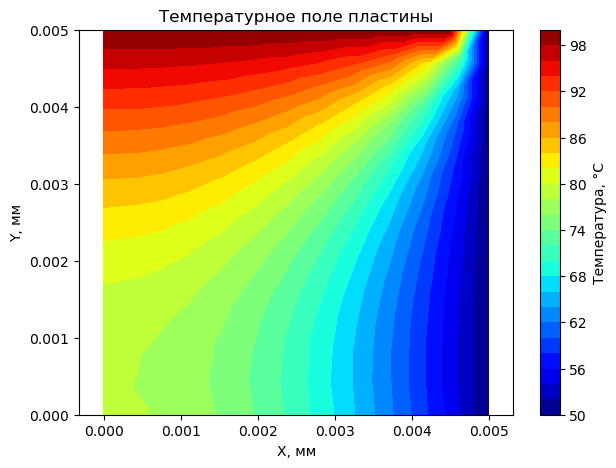

In [40]:
fig, ax = plt.subplots(figsize=(7, 5))

plt.tricontourf(pnts[:, 0], pnts[:, 1], elms, T_sol3,
                levels=30, cmap='jet')

plt.colorbar(label='Температура, °C')
plt.axis('equal')
plt.xlabel('X, мм')
plt.ylabel('Y, мм')
plt.title('Температурное поле пластины')
plt.show()


## 9. Выводы по результатам семинара

В ходе семинара мы разработали собственную программу для расчёта **стационарного температурного поля пластины методом конечных элементов**, используя Python, NumPy и Gmsh.

Последовательно были рассмотрены основные этапы конечно-элементного анализа:

1. **Построение конечно-элементной модели.** Из геометрической модели получена сетка линейных треугольных элементов, определены координаты узлов и связность элементов.
2. **Формирование элементных матриц.** На основе линейной аппроксимации температурного поля и вариационной постановки задачи получена матрица теплопроводности треугольного элемента.
3. **Сборка глобальной системы.** Элементные матрицы объединены в глобальную матрицу теплопроводности с учётом общих узлов соседних элементов.
4. **Задание граничных условий.** Реализованы условия I, II и III рода, определяющие температуру, заданный тепловой поток и конвективный теплообмен на границах пластины.
5. **Решение и визуализация.** Сформированная система линейных алгебраических уравнений решена численно, а полученное поле узловых температур представлено графически.

### Основные результаты

Мы убедились, что **все три вида граничных условий учитываются в единой системе уравнений**, но различаются способом реализации:

- **ГУ I рода** задают известные значения узловых температур и требуют соответствующего преобразования системы.
- **ГУ II рода** формируют дополнительные составляющие вектора тепловой нагрузки.
- **ГУ III рода** формируют дополнительные составляющие как глобальной матрицы, так и вектора правой части.

При этом все рассмотренные выражения получены из единой вариационной постановки задачи теплопроводности — **условия стационарности функционала по неизвестным узловым температурам**.
